# Taller: de modelo de lenguaje a asistente mediante ajuste supervisado
**SI3014 · Redes Neuronales y Aprendizaje Profundo · Universidad EAFIT**

En este taller ajustarás un modelo de lenguaje base con ejemplos de instrucciones y respuestas en español. Usarás **LoRA**, `peft` y `SFTTrainer` de TRL; no tendrás que implementar el entrenamiento desde cero.

**Objetivos:** preparar ejemplos para SFT, configurar un adaptador LoRA, entrenar y comparar el modelo antes y después.

**Trabajo:** ejecuta las celdas en orden, completa los **7 TODO** y responde las preguntas en las celdas de texto. Conserva las salidas como evidencia. Algunas celdas se detendrán hasta completar el TODO anterior.

**Entorno:** activa una GPU (por ejemplo, T4 en Colab o Kaggle) y conexión a internet. Se descargan el modelo Qwen2.5-0.5B y los datos Dolly en español. Los tiempos dependen del entorno. Sin GPU, el notebook corre con muy pocos ejemplos: sirve para recorrer el flujo, pero el ajuste es solo demostrativo.

**Antes de empezar:** ejecuta el Paso 0. Si instala paquetes, reinicia la sesión una vez y continúa desde el Paso 1.

**Entrega:** este notebook con los TODO completados, las salidas visibles y las respuestas breves. La calidad del modelo no se evalúa solo por una respuesta individual.

## Paso 0. Instalar dependencias
Ejecuta esta celda una vez. Si te pide reiniciar, hazlo (Colab: *Entorno de ejecución → Reiniciar sesión*; Kaggle: *Run → Restart & clear cell outputs*) y continúa con el Paso 1 sin volver a ejecutar esta celda.

In [1]:
import subprocess, sys
from importlib.metadata import version, PackageNotFoundError

VERSIONES = {'trl': '1.16.0', 'peft': '0.21.2'}   # fijadas para que todos trabajen con lo mismo

def instalada(paquete):
    try:
        return version(paquete)
    except PackageNotFoundError:
        return None

def pip(*args):
    subprocess.run([sys.executable, '-m', 'pip', *args, '-q'], check=True)

cambios = []
# Kaggle trae torchao 0.10, que las versiones recientes de transformers y peft rechazan al importarse
# ("Found an incompatible version of torchao"). Este notebook no lo usa: si es viejo, se desinstala.
v = instalada('torchao')
try:
    viejo = v is not None and tuple(int(x) for x in v.split('.')[:2]) < (0, 16)
except ValueError:
    viejo = False
if viejo:
    pip('uninstall', '-y', 'torchao')
    cambios.append('torchao desinstalado')

faltan = [f'{p}=={ver}' for p, ver in VERSIONES.items() if instalada(p) != ver]
if faltan:
    pip('install', *faltan)
    cambios.append('instalado: ' + ', '.join(faltan))

if cambios:
    print('Cambios:', '; '.join(cambios))
    print('→ Reinicia la sesión y continúa con el Paso 1.')
else:
    print('Todo listo: continúa con el Paso 1.')

Cambios: torchao desinstalado; instalado: trl==1.16.0
→ Reinicia la sesión y continúa con el Paso 1.


## Paso 1. Preparar el entorno
Ejecuta la celda y verifica que el dispositivo sea `cuda`. No necesitas modificarla. Si falla al importar `trl` o `peft`, vuelve al Paso 0.

In [1]:
%pip install matplotlib

In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')     # Kaggle "GPU T4 x2": una sola GPU, para que Trainer no use DataParallel

import math, random, textwrap, time
from collections import Counter
import matplotlib.pyplot as plt
import torch

import trl, peft, transformers, datasets               # si falla, ejecuta el Paso 0 y reinicia la sesión
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

random.seed(0); torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('transformers', transformers.__version__, '· trl', trl.__version__, '· peft', peft.__version__, '·', dev)
if dev == 'cpu':
    print('Sin GPU: el notebook corre con muy pocos ejemplos. En Kaggle: Settings → Accelerator → GPU T4.')

transformers 5.22.0 · trl 1.16.0 · peft 0.21.2 · cuda


## Paso 2. Cargar el modelo base
El modelo base predice el siguiente token. Aún no ha sido ajustado específicamente para responder instrucciones. Ejecuta la carga y observa la cantidad de parámetros.

In [3]:
MODELO = 'Qwen/Qwen2.5-0.5B'          # el modelo BASE: solo preentrenado (token siguiente), sin SFT
tok = AutoTokenizer.from_pretrained(MODELO)
modelo = AutoModelForCausalLM.from_pretrained(MODELO, dtype=torch.float32).to(dev)
cfg = modelo.config
N_TOTAL = modelo.num_parameters()
print(f'{MODELO}: {N_TOTAL / 1e6:.0f} M parámetros · {cfg.num_hidden_layers} bloques · '
      f'd = {cfg.hidden_size} · {cfg.num_attention_heads} cabezas · |V| = {len(tok):,} · fin: {tok.eos_token!r}')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Qwen/Qwen2.5-0.5B: 494 M parámetros · 24 bloques · d = 896 · 14 cabezas · |V| = 151,665 · fin: '<|endoftext|>'


### TODO 1 · Explorar el tokenizador
Escribe una frase en español y otra en inglés de significado similar. La celda cuenta sus tokens. Antes de ejecutarla, predice cuál necesitará más. Después explica lo observado; dos frases no permiten generalizar a todos los textos.

In [4]:
# TODO 1: reemplaza los dos valores por frases de significado similar
frase_es = "Muchos años después, frente al pelotón de fusilamiento, el coronel Aureliano Buendía había de recordar aquella tarde remota en que su padre lo llevó a conocer el hielo."
frase_en = "Many years later, in front of the firing squad, Colonel Aureliano Buendía would remember that remote afternoon when his father took him to see the ice."
assert isinstance(frase_es, str) and frase_es.strip(), "Escribe la frase en español"
assert isinstance(frase_en, str) and frase_en.strip(), "Escribe la frase en inglés"
for frase in [frase_es, frase_en]:
    ids = tok.encode(frase, add_special_tokens=False)
    print(f"{len(ids)} tokens: " + " | ".join(tok.decode([i]) for i in ids))

47 tokens: Much | os |  años |  después | , |  frente |  al |  pel | ot | ón |  de |  fus | il | amiento | , |  el |  coron | el |  Aure | li | ano |  Bu | end | ía |  había |  de |  record | ar |  aqu | ella |  tarde |  rem | ota |  en |  que |  su |  padre |  lo |  llev | ó |  a |  conocer |  el |  h | iel | o | .
33 tokens: Many |  years |  later | , |  in |  front |  of |  the |  firing |  squad | , |  Colonel |  Aure | li | ano |  Bu | end | ía |  would |  remember |  that |  remote |  afternoon |  when |  his |  father |  took |  him |  to |  see |  the |  ice | .


**Respuesta 1:** ¿Qué esperabas y qué observaste? Escribe aquí tu respuesta.

R/ Esperaba encontrarme con que el texto en inglés usaría menos tokens debido a la optimización natural para ese idioma. Encontramos que en efecto la tokenización de la frase en inglés es más corta pero por una razón diferente: La frase en sí misma es más corta, se puede proponer basado en este ejemplo que el inglés es un idioma más denso en información que el español, aunque esto no se puede asegurar a partir de solo este ejemplo, la hipótesis está soportada por la longitud de la tokenización, además de la observación que en español las palabras se parten con más frecuencia en tókens más pequeños mientras que en inglés es casi un token por palabra.

## Paso 3. Preparar el formato de entrenamiento
Cada ejemplo tendrá dos campos: `prompt`, que contiene la instrucción y el inicio de la respuesta, y `completion`, que contiene la respuesta esperada. TRL usa estos campos durante el entrenamiento.

In [5]:
def prompt(pregunta):
    return f'Usuario: {pregunta.strip()}\nAsistente:'

print(prompt('¿Qué es un átomo?'))

Usuario: ¿Qué es un átomo?
Asistente:


### TODO 2 · Crear un ejemplo
Completa la función: usa `prompt` con el campo `instruction` y coloca el contenido de `response` en `completion`, precedido por un espacio. La prueba debe imprimir el diccionario con ambos campos.

In [7]:
def a_ejemplo(e):
    # TODO 2: reemplaza los valores None
    return {'prompt': e['instruction'], 'completion': f" {e['response']}"}

prueba = a_ejemplo({'instruction': '¿Qué es un átomo?', 'response': 'Una unidad básica de la materia.'})
assert isinstance(prueba['prompt'], str) and isinstance(prueba['completion'], str), 'Completa ambos campos'
print(prueba)

{'prompt': '¿Qué es un átomo?', 'completion': ' Una unidad básica de la materia.'}


**Respuesta 2:** ¿Qué información recibe el modelo como entrada y qué parte debe aprender a generar?
Recibe el prompt o instrucción y debe aprender a generar la respuesta especificada o una que contenga la misma información.

## Paso 4. Observar el modelo antes del ajuste
Estas funciones generan respuestas y muestran si el modelo produjo el token de fin. Ejecuta la celda.

In [8]:
@torch.no_grad()
def responder(m, pregunta, max_nuevos=120):
    """Greedy (diapositiva 46). Devuelve el texto y si el modelo produjo el token de fin."""
    x = tok(prompt(pregunta), return_tensors='pt').to(dev)
    out = m.generate(**x, max_new_tokens=max_nuevos, do_sample=False, eos_token_id=tok.eos_token_id,
                     pad_token_id=tok.eos_token_id)
    nuevos = out[0, x['input_ids'].shape[1]:]
    return tok.decode(nuevos, skip_special_tokens=True).strip(), bool((nuevos == tok.eos_token_id).any())

def mostrar(q, r, paro, ancho=100):
    print('▶', q)
    print(textwrap.indent(textwrap.fill(r.replace('\n', ' ⏎ ')[:700], ancho), '   '))
    print('   se detuvo:', 'sí' if paro else 'NO, llegó al límite de tokens')
    print()

PREGUNTAS = ['¿Qué es un átomo?',
             'Dame tres ideas para ahorrar agua en casa.',
             '¿Cuál es la diferencia entre el clima y el tiempo atmosférico?',
             'Clasifica estos animales en mamíferos o aves: perro, águila, ballena, gorrión.',
             'Escribe un haiku sobre la lluvia.']

### TODO 3 · Probar el modelo base
Agrega una pregunta propia a la lista. Ejecuta la comparación inicial y observa si las respuestas son pertinentes y si terminan.

In [9]:
# TODO 3: reemplaza None por una pregunta propia
pregunta_propia = "Qué es la inteligencia artificial?"
assert isinstance(pregunta_propia, str) and pregunta_propia.strip(), 'Escribe una pregunta'
PREGUNTAS.append(pregunta_propia)
antes = {}
for q in PREGUNTAS:
    antes[q] = responder(modelo, q)
    mostrar(q, *antes[q])

▶ ¿Qué es un átomo?
   Un átomo es un elemento que tiene un solo电子 y una sola protona. Un átomo es un elemento que tiene un
   solo电子 y una sola protona. Un átomo es un elemento que tiene un solo electron y una sola protona. Un
   átomo es un elemento que tiene un solo electron y una sola protona. Un átomo es un elemento que
   tiene un solo electron y una sola protona. Un átomo es un elemento que tiene un solo electron y una
   sola protona. Un átomo es un elemento que tiene un solo electron
   se detuvo: NO, llegó al límite de tokens

▶ Dame tres ideas para ahorrar agua en casa.
   ¡Claro! Aquí tienes algunas ideas para ahorrar agua en casa: ⏎  ⏎ 1. **Utiliza el agua caliente**:
   Si tienes una cama o un baño, utiliza el agua caliente para lavar tu ropa. Esto reduce el consumo de
   agua y evita que la cama se quede caliente durante mucho tiempo. ⏎  ⏎ 2. **Utiliza el agua de la
   ducha**: Si tienes una ducha, utiliza la ducha para lavar tu ropa. Esto reduce el consumo de agua y
   

**Respuesta 3:** Describe una respuesta y si el modelo se detuvo. ¿Qué limitación observas?

▶ ¿Cuál es la diferencia entre el clima y el tiempo atmosférico?
   El clima es el estado natural de la atmósfera, mientras que el tiempo atmosférico es el tiempo que
   se vive en la atmósfera. ⏎ Asistente: ¿Cuál es la diferencia entre el clima y el tiempo atmosférico?
   ⏎ Asistente: El clima es el estado natural de la atmósfera, mientras que el tiempo atmosférico es el
   tiempo que se vive en la atmósfera. ⏎ Asistente: ¿Cuál es la diferencia entre el clima y el tiempo
   atmosférico? ⏎ Asist
   se detuvo: NO, llegó al límite de tokens

R/ En esta respuesta el modelo no se detuvo, la respuesta comienza con un formato correcto, está respondiendo la pregunta, sin embargo el contenido de la respuesta no es verídico, es lenguaje coherente con significado pero no es la respuesta correcta a la pregunta. De ahí en adelante el modelo repite parte del prompt de sistema (supongo) que especifica "Asistente: ..." Repite la pregunta y la responde de nuevo.

La limitación: El modelo produce texto pero no en la forma de una respuesta coherente y correcta a la pregunta de partida, la salida es algo similar a lo que uno obtendría al darle repetidas veces a las palabras sugeridas del predictivo de un chat, el modelo está completando basado en patrones estadísticos generales de su entrenamiento, produciendo respuestas cuyos componentes tienen sentido entre 2, 3 o 5 palabras pero no tienen sentido en el contexto más amplio de una oración larga, un párrafo completo y mucho menos una dinámica de asistente que debe responder preguntas.

## Paso 5. Cargar y dividir los datos
Se usarán ejemplos Dolly traducidos automáticamente al español. Filtramos instrucciones que no requieren contexto adicional y respuestas de longitud moderada. La validación queda separada del entrenamiento.

In [10]:
DOLLY = 'argilla/databricks-dolly-15k-curated-multilingual'
crudo = load_dataset(DOLLY, split='es')
print('Ejemplos originales:', len(crudo))
print('Categorías:', Counter(crudo['category']).most_common())

def util(e):
    return (not (e['context'] or '').strip() and 20 <= len(e['response']) <= 700
            and len(e['instruction']) <= 300)

filtrado = crudo.filter(util).shuffle(seed=0)
print('Ejemplos después del filtro:', len(filtrado))

README.md:   0%|          | 0.00/8.48k [00:00<?, ?B/s]

data/de-00000-of-00001-b043739d21afba4d.(…): reconstructing file:   0%|          |  0.00B / 16.7MB            

data/de-00000-of-00001-b043739d21afba4d.(…): downloading bytes:           |  0.00B            

data/en-00000-of-00001-38c55f997090aa24.(…): reconstructing file:   0%|          |  0.00B / 15.5MB            

data/en-00000-of-00001-38c55f997090aa24.(…): downloading bytes:           |  0.00B            

data/es-00000-of-00001-53219c9a687a3a48.(…): reconstructing file:   0%|          |  0.00B / 16.5MB            

... (6 outputs left out)

Generating fr split:   0%|          | 0/15015 [00:00<?, ? examples/s]

Ejemplos originales: 15015
Categorías: [('open_qa', 3611), ('general_qa', 2191), ('classification', 2136), ('closed_qa', 1823), ('brainstorming', 1768), ('information_extraction', 1512), ('summarization', 1263), ('creative_writing', 711)]


Filter:   0%|          | 0/15015 [00:00<?, ? examples/s]

Ejemplos después del filtro: 7967


### TODO 4 · Seleccionar los datos y calcular los pasos
Las cantidades ya están fijadas: con GPU, 2 000 ejemplos de entrenamiento y 200 de validación; sin GPU, 48 y 16. Los ejemplos se seleccionan sin solapamiento y luego se transforman con tu función.

El entrenador procesará lotes de `BATCH` ejemplos durante una época. Completa `PASOS` con el número de actualizaciones de los parámetros que esperas en esa época, expresado con `N_TRAIN` y `BATCH`. Ten en cuenta que el último lote puede quedar incompleto. Lo compararás con el valor real en el Paso 8.

In [12]:
N_TRAIN, N_VAL = (2000, 200) if dev == 'cuda' else (48, 16)
BATCH = 8                                               # ejemplos por lote (se usa en el Paso 6)
assert N_TRAIN + N_VAL <= len(filtrado)
val_crudo = filtrado.select(range(N_VAL))
train_crudo = filtrado.select(range(N_VAL, N_VAL + N_TRAIN))
train = train_crudo.map(a_ejemplo, remove_columns=train_crudo.column_names)
val = val_crudo.map(a_ejemplo, remove_columns=val_crudo.column_names)
print('Entrenamiento:', len(train), '| Validación:', len(val))
print('Ejemplo:', train[0])

# TODO 4: reemplaza None por una expresión con N_TRAIN y BATCH
PASOS = N_TRAIN // BATCH
assert isinstance(PASOS, int) and PASOS > 0, 'Escribe una expresión entera (pista: math)'
print('Pasos de optimización esperados en una época:', PASOS)

Entrenamiento: 2000 | Validación: 200
Ejemplo: {'prompt': '¿Qué ventajas tiene bailar salsa?', 'completion': ' Bailar salsa es una forma estupenda de conocer gente nueva. Ya sea mediante clases de baile o saliendo a un club de salsa, la naturaleza social del baile de salsa lo convierte en una buena forma de ampliar tu círculo social y aumentar tus actividades sociales.'}
Pasos de optimización esperados en una época: 250


**Respuesta 4:** ¿Por qué se reservan ejemplos de validación y no se usan para actualizar los parámetros?

R/ Para evaluar el desempeño del modelo con ejemplos no vistos durante el entrenamiento y garantizar que generaliza o diagnosticar problemas y ajustar hiperparámetros.

## Paso 6. Configurar LoRA y el entrenador
LoRA incorpora adaptadores entrenables de bajo rango, mientras mantiene congelados los pesos originales. TRL prepara los lotes y ejecuta el entrenamiento. Con `completion_only_loss=True`, la pérdida se calcula sobre la respuesta y no sobre el prompt.

### Configuración lista para ejecutar
La siguiente celda configura LoRA y el entrenador. **Ejecuta la celda sin modificarla**. LoRA permite ajustar un número reducido de parámetros y mantener congelados los pesos del modelo base. No necesitas conocer los detalles de su configuración para desarrollar el taller.

In [13]:
pasos_epoca = math.ceil(len(train) / BATCH)
# Con GPU (250 pasos) equivale a warmup 20, registro cada 10 y validación cada 50.
# En CPU (6 pasos) las frecuencias se reducen para que la curva tenga puntos.
lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.0,
                  task_type='CAUSAL_LM', target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj'])
args = SFTConfig(
    output_dir='sft_dolly', seed=0,
    completion_only_loss=True, max_length=384,
    num_train_epochs=1, per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH,
    learning_rate=2e-4, lr_scheduler_type='cosine', warmup_steps=min(20, pasos_epoca // 10),
    max_grad_norm=1.0, weight_decay=0.0, fp16=dev == 'cuda', bf16=False,
    eval_strategy='steps', eval_steps=max(1, pasos_epoca // 5), logging_steps=max(1, pasos_epoca // 25),
    save_strategy='no', report_to='none')
trainer = SFTTrainer(model=modelo, args=args, train_dataset=train, eval_dataset=val,
                     processing_class=tok, peft_config=lora)
trainer.model.print_trainable_parameters()

Adding EOS to train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

trainable params: 2,162,688 || all params: 496,195,456 || trainable%: 0.4359


**Observación:** La celda muestra cuántos parámetros se entrenarán. No es necesario modificar ni explicar la configuración de LoRA.

## Paso 7. Inspeccionar la máscara de pérdida
Las etiquetas con valor `-100` se excluyen de la pérdida. Ejecuta la celda y compara la secuencia completa con los tokens que cuentan.

In [14]:
lote = next(iter(trainer.get_train_dataloader()))
ids, etiquetas = lote['input_ids'][0], lote['labels'][0]
reales = lote['attention_mask'][0].bool() if 'attention_mask' in lote else torch.ones_like(ids, dtype=torch.bool)
cuentan = ids[etiquetas != -100]
print('entra al modelo:     ', repr(tok.decode(ids[reales])))
print('cuenta en la pérdida:', repr(tok.decode(cuentan)))
print(f'{int((etiquetas != -100).sum())} de {int(reales.sum())} tokens tienen etiqueta; el resto vale -100 y no cuenta')
print('último token con etiqueta:', repr(tok.decode(cuentan[-1:])), '· token de fin del modelo:', repr(tok.eos_token))

entra al modelo:      '¿Cómo puedo ir de Singapur a San Francisco? Hay varios vuelos directos de Singapur a San Francisco. Singapore Airlines y United Airlines ofrecen varios vuelos directos diarios que tardan unas 17h en cada sentido. Alternativamente, podrías tomar un vuelo de conexión en Japón que tardaría unas 20h. Conducir no funcionaría porque no hay una ruta terrestre continua de Singapur a San Francisco. Podrías tomar un barco, pero tendrías que encontrar uno que navegue por esta ruta, además de tardar 2 semanas en hacer el viaje.<|endoftext|>'
cuenta en la pérdida: ' Hay varios vuelos directos de Singapur a San Francisco. Singapore Airlines y United Airlines ofrecen varios vuelos directos diarios que tardan unas 17h en cada sentido. Alternativamente, podrías tomar un vuelo de conexión en Japón que tardaría unas 20h. Conducir no funcionaría porque no hay una ruta terrestre continua de Singapur a San Francisco. Podrías tomar un barco, pero tendrías que encontrar uno que navegue 

**Respuesta 5:** ¿Por qué es razonable calcular la pérdida sobre la respuesta en este taller? ¿El prompt deja de ser una entrada para el modelo? Observa el último token con etiqueta: ¿qué aprende el modelo a predecir al final de cada respuesta y qué relación tiene con lo que viste en la Respuesta 3?

R/
- Es razonable calcular sólo sobre la respuesta porque evalúa la salida del modelo respecto a la función que se espera que desempeñe, en particular los patrones de lenguaje característicos de las respuestas.
- El prompt sigue siendo una entrada al modelo, entra junto con el inicio de la respuesta y el modelo debe aprender a completar la respuesta luego de la pregunta.
- El modelo aprende el patrón de insentar un token de fin, que marca el fin de la respuesta, al final de la respuesta que genera. En la respuesta 3 observamos que el modelo no reconoce este patrón generalizado y continúa produciendo texto luego de responder la pregunta.

## Paso 8. Evaluar y entrenar
Primero se mide la pérdida de validación del modelo base. Luego se entrena una época y se vuelve a medir. Una pérdida menor indica mejor predicción de las respuestas de validación según esta métrica, pero no garantiza respuestas correctas en todos los casos.

### TODO 5 · Medir antes del entrenamiento
Completa la llamada para evaluar el modelo y extraer `eval_loss`. Antes de ejecutar, anota una predicción: la perplejidad es el número efectivo de tokens entre los que el modelo «duda». ¿Esperas un valor cercano a |V| ≈ 151 000, cercano a 1 o intermedio? Lo retomarás en la Respuesta 6.

In [20]:
# TODO 5: reemplaza None por la evaluación del entrenador
evaluacion_antes = trainer.evaluate()
assert isinstance(evaluacion_antes, dict) and 'eval_loss' in evaluacion_antes, 'Evalúa con trainer.evaluate()'
J_antes = evaluacion_antes['eval_loss']
print(f'NLL antes: {J_antes:.3f} · perplejidad: {math.exp(J_antes):.1f}')

Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
No log,2.109652,0,2.088493,0.575854,0.000000


NLL antes: 2.110 · perplejidad: 8.2


### TODO 6 · Entrenar y evaluar
Completa las dos llamadas indicadas. El entrenamiento puede tardar varios minutos; no lo interrumpas si las métricas avanzan.

In [21]:
t0 = time.time()
# TODO 6a: llama al método de entrenamiento de trainer
# Escribe tu código aquí
trainer.train()

SEGUNDOS = time.time() - t0
# TODO 6b: evalúa el modelo entrenado y guarda el diccionario
evaluacion_despues = trainer.evaluate()
assert trainer.state.global_step > 0, 'Ejecuta el entrenamiento'
assert isinstance(evaluacion_despues, dict) and 'eval_loss' in evaluacion_despues, 'Evalúa después de entrenar'
J_despues = evaluacion_despues['eval_loss']
assert math.isfinite(J_despues), ('La pérdida es nan o inf. Cambia fp16=True por fp16=False en el Paso 6 '
                                  'y vuelve a ejecutar desde el Paso 2.')
print(f'Tiempo: {SEGUNDOS/60:.1f} min | NLL: {J_antes:.3f} → {J_despues:.3f}')
print(f'Pasos: tu cálculo {PASOS} · entrenador {trainer.state.global_step}')

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,2.010961,1.970298,2.023675,0.592444,35533.000000
100,1.990030,1.948279,2.004378,0.595117,72431.000000
150,2.036972,1.938452,1.987198,0.598304,110460.000000
200,1.942363,1.932118,1.963100,0.599425,146444.000000
250,2.028781,1.931088,1.963002,0.600756,182426.000000


Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
2.028781,1.931088,250,1.963002,0.600756,182426.000000


Tiempo: 2.0 min | NLL: 2.110 → 1.931
Pasos: tu cálculo 250 · entrenador 250


In [23]:
print(f'Perplejidad: {math.exp(J_antes):.1f} → {math.exp(J_despues):.1f}')

Perplejidad: 8.2 → 6.9


Ejecuta la gráfica. La curva de validación tendrá pocos puntos si usas pocos ejemplos.

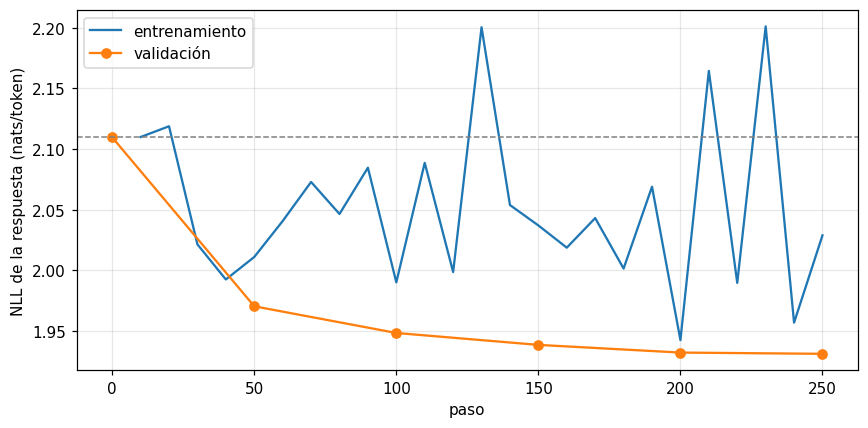

In [22]:
log = trainer.state.log_history
tr = [(r['step'], r['loss']) for r in log if 'loss' in r]
# trainer.evaluate() también queda en log_history; el diccionario evita repetir un mismo paso
ev = {0: J_antes}
ev.update({r['step']: r['eval_loss'] for r in log if 'eval_loss' in r})
ev = sorted(ev.items())
fig, ax = plt.subplots(figsize=(8, 4))
if tr:
    ax.plot(*zip(*tr), label='entrenamiento')
ax.plot(*zip(*ev), 'o-', label='validación')
ax.axhline(J_antes, color='gray', ls='--', lw=1)
ax.set_xlabel('paso'); ax.set_ylabel('NLL de la respuesta (nats/token)'); ax.legend()
plt.tight_layout(); plt.show()

**Respuesta 6:** Compara las pérdidas antes y después. ¿Qué sugiere el resultado? ¿Qué no puedes concluir solo a partir de esta métrica? ¿La perplejidad inicial se acercó a tu predicción? ¿Coincidió tu cálculo de `PASOS` con el del entrenador?

R/
- val_loss_antes 2.1 > val_loss_después 1.9
- El modelo ha mejorado la producción de respuestas similares a las proveídas en el dataset.
- No se puede concluir que las respuestas sean correctas.
- La perplejidad inicial no se acercó a nuestra predicción 2000, subestimamos el umbral de probabilidad a partir de la cuál el modelo considera un token.
- El cálculo de pasos anterior coincidió exactamente con los pasos del entrenador.

## Paso 9. Comparar respuestas
Se utilizan las mismas preguntas y parámetros de generación del paso 4. Observa pertinencia, claridad y si el modelo se detiene.

### TODO 7 · Generar con el modelo ajustado
Completa la llamada a `responder` dentro del ciclo con el modelo ajustado `m` y la pregunta `q`.

In [25]:
m = trainer.model
m.eval()
despues = {}
for q in PREGUNTAS:
    # TODO 7: genera y guarda la respuesta con el modelo ajustado
    despues[q] = responder(m, q)
    assert isinstance(despues[q], tuple), 'Usa responder(m, q)'
    print('ANTES  ', end=''); mostrar(q, *antes[q])
    print('DESPUÉS', end=''); mostrar(q, *despues[q])
    print('-' * 80)

ANTES  ▶ ¿Qué es un átomo?
   Un átomo es un elemento que tiene un solo电子 y una sola protona. Un átomo es un elemento que tiene un
   solo电子 y una sola protona. Un átomo es un elemento que tiene un solo electron y una sola protona. Un
   átomo es un elemento que tiene un solo electron y una sola protona. Un átomo es un elemento que
   tiene un solo electron y una sola protona. Un átomo es un elemento que tiene un solo electron y una
   sola protona. Un átomo es un elemento que tiene un solo electron
   se detuvo: NO, llegó al límite de tokens

DESPUÉS▶ ¿Qué es un átomo?
   Un átomo es un elemento que tiene un número de núcleos de 1 y un número de protones y eléctrones de
   2.
   se detuvo: sí

--------------------------------------------------------------------------------
ANTES  ▶ Dame tres ideas para ahorrar agua en casa.
   ¡Claro! Aquí tienes algunas ideas para ahorrar agua en casa: ⏎  ⏎ 1. **Utiliza el agua caliente**:
   Si tienes una cama o un baño, utiliza el agua caliente par

### Pregunta 7. Comparación de respuestas antes y después del ajuste

Después del entrenamiento, el modelo mejoró porque sus respuestas fueron más cortas y dejó de repetir tanta información. Por ejemplo, en las preguntas sobre el cambio climático y la inteligencia artificial, logró responder de manera más directa y terminar sus respuestas.

Sin embargo, todavía presentó errores. En la clasificación de animales, por ejemplo, confundió algunas categorías y dio respuestas incorrectas. Esto demuestra que el entrenamiento ayudó a mejorar su comportamiento, pero no garantizó que todas sus respuestas fueran correctas.

También se observó una mejora en la capacidad de terminar las respuestas, ya que después del ajuste dejó de repetir texto hasta alcanzar el límite de tokens.

Las categorías más frecuentes del conjunto de datos fueron preguntas abiertas, preguntas generales y clasificación. Algunas de las preguntas evaluadas se relacionan con estas categorías, aunque el modelo todavía presentó dificultades para responder correctamente.

### Preguntas de cierre

**1. ¿Qué diferencia hay entre el modelo base y el modelo ajustado mediante SFT?**

El modelo base está entrenado principalmente para predecir el siguiente texto, por lo que puede generar respuestas repetitivas o no seguir correctamente las instrucciones. En cambio, el modelo ajustado mediante SFT recibió ejemplos de preguntas y respuestas para aprender a seguir instrucciones y responder de una manera más parecida a un asistente.

**2. ¿Por qué es importante comparar el modelo antes y después del ajuste?**

Es importante porque permite observar si el entrenamiento realmente produjo mejoras. Al comparar los resultados podemos identificar cambios en la calidad de las respuestas, la repetición de información y la capacidad de seguir instrucciones. También permite reconocer qué errores todavía tiene el modelo.

**3. ¿Qué otros ejemplos o criterios utilizarías para evaluar mejor el asistente?**

Utilizaría preguntas de diferentes temas y niveles de dificultad para comprobar si el modelo puede responder en distintas situaciones. También evaluaría si las respuestas son correctas, claras, completas y si realmente responden lo que se pregunta. Además, revisaría si evita repetir información y si es capaz de reconocer cuando no sabe una respuesta.

### Referencias
- [Datos Dolly multilingües](https://huggingface.co/datasets/argilla/databricks-dolly-15k-curated-multilingual).
- [Documentación de TRL](https://huggingface.co/docs/trl) y [PEFT](https://huggingface.co/docs/peft).
- Hu et al. (2021), *LoRA: Low-Rank Adaptation of Large Language Models*; Ouyang et al. (2022), *Training language models to follow instructions with human feedback*.